## Implement a reinforcement learning algorithm using neural networks.

In [7]:
import numpy as np
import gym
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt

In [8]:
# Create CartPole environment
env = gym.make("CartPole-v1")

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

print("State size:", state_dim)
print("Action size:", action_dim)

State size: 4
Action size: 2


In [9]:
model = tf.keras.Sequential([
    layers.Dense(24, activation='relu'),
    layers.Dense(24, activation='relu'),
    layers.Dense(action_dim, activation='linear')
])

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
loss_fn = tf.keras.losses.MeanSquaredError()

In [10]:
def choose_action(state, epsilon=0.1):
    if np.random.rand() < epsilon:
        return np.random.choice(action_dim)     # Explore
    state = state.reshape(1, -1)
    q_values = model(state)
    return np.argmax(q_values.numpy()[0])       # Exploit

In [11]:
episodes = 200
gamma = 0.95
reward_history = []

for ep in range(episodes):
    state, _ = env.reset()
    done = False
    total_reward = 0
    
    while not done:
        action = choose_action(state)
        
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        
        # Q-learning target
        target = reward + gamma * np.max(model(next_state.reshape(1, -1)))
        
        # Update Q-values
        q_vals = model(state.reshape(1, -1)).numpy()
        q_vals[0][action] = target
        
        with tf.GradientTape() as tape:
            pred = model(state.reshape(1, -1))
            loss = loss_fn(q_vals, pred)
        
        grads = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))
        
        state = next_state
        total_reward += reward
    
    reward_history.append(total_reward)
    print(f"Episode {ep+1} Reward: {total_reward}")

Episode 1 Reward: 9.0
Episode 2 Reward: 10.0
Episode 3 Reward: 9.0
Episode 4 Reward: 12.0
Episode 5 Reward: 10.0
Episode 6 Reward: 9.0
Episode 7 Reward: 11.0
Episode 8 Reward: 10.0
Episode 9 Reward: 12.0
Episode 10 Reward: 11.0
Episode 11 Reward: 9.0
Episode 12 Reward: 8.0
Episode 13 Reward: 13.0
Episode 14 Reward: 9.0
Episode 15 Reward: 11.0
Episode 16 Reward: 10.0
Episode 17 Reward: 11.0
Episode 18 Reward: 9.0
Episode 19 Reward: 9.0
Episode 20 Reward: 11.0
Episode 21 Reward: 10.0
Episode 22 Reward: 10.0
Episode 23 Reward: 10.0
Episode 24 Reward: 9.0
Episode 25 Reward: 12.0
Episode 26 Reward: 10.0
Episode 27 Reward: 11.0
Episode 28 Reward: 9.0
Episode 29 Reward: 9.0
Episode 30 Reward: 9.0
Episode 31 Reward: 9.0
Episode 32 Reward: 9.0
Episode 33 Reward: 8.0
Episode 34 Reward: 10.0
Episode 35 Reward: 10.0
Episode 36 Reward: 9.0
Episode 37 Reward: 8.0
Episode 38 Reward: 10.0
Episode 39 Reward: 10.0
Episode 40 Reward: 18.0
Episode 41 Reward: 8.0
Episode 42 Reward: 11.0
Episode 43 Reward: 

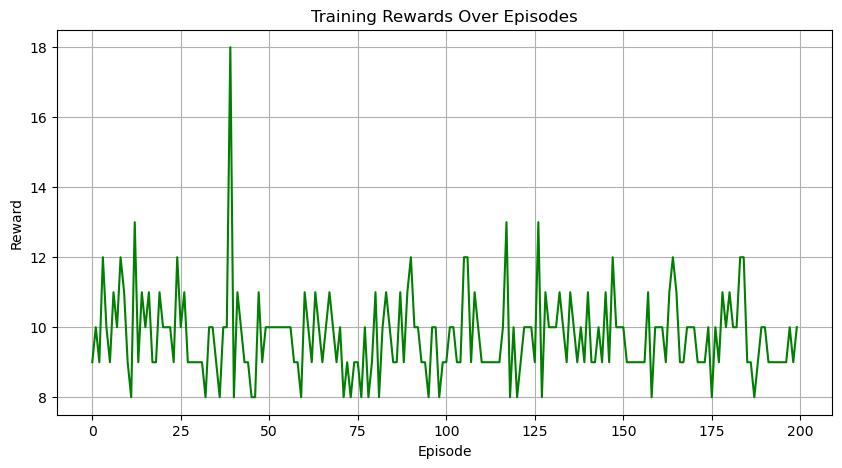

In [13]:
plt.figure(figsize=(10,5))
plt.plot(reward_history, color="green")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("Training Rewards Over Episodes")
plt.grid(True)
plt.show()